# PRML Lab 9 — Clustering
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

In [1]:
import gzip
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)
SEED = 56
sns.set_theme(style='whitegrid')
results = {}

def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

# Question 1 — k-means on the Wine dataset

In [2]:
WINE_COLS = ['Alcohol', 'Malic acid', 'Ash', 'Alcalinity of ash', 'Magnesium', 'Total phenols', 'Flavanoids',
             'Nonflavanoid phenols', 'Proanthocyanins', 'Color intensity', 'Hue', 'OD280/OD315', 'Proline']
wine = pd.read_csv('data/wine.data', header=None, names=['cultivar'] + WINE_COLS)
print(wine.shape, '| missing:', wine.isna().sum().sum(), '| duplicates:', wine.duplicated().sum())
wine[WINE_COLS].describe().T[['mean', 'std', 'min', 'max']].round(2)

(178, 14) | missing: 0 | duplicates: 0


,mean,std,min,max
Alcohol,13.00,0.81,11.03,14.83
Malic acid,2.34,1.12,0.74,5.80
Ash,2.37,0.27,1.36,3.23
Alcalinity of ash,19.49,3.34,10.60,30.00
Magnesium,99.74,14.28,70.00,162.00
Total phenols,2.30,0.63,0.98,3.88
Flavanoids,2.03,1.00,0.34,5.08
Nonflavanoid phenols,0.36,0.12,0.13,0.66
Proanthocyanins,1.59,0.57,0.41,3.58
Color intensity,5.06,2.32,1.28,13.00


**Pre-processing.** 178 wines with 13 chemical measurements and no missing values. The first column is the cultivar label. Clustering is unsupervised, so the label is **set aside** and only used at the end to check what the clusters found. The features are on wildly different scales (Proline ≈ 750 vs Hue ≈ 1), and k-means uses Euclidean distance, so without scaling Proline alone would decide every cluster. Every feature is therefore **standardised** to zero mean and unit variance.

In [3]:
Xw = StandardScaler().fit_transform(wine[WINE_COLS])
cultivar = wine['cultivar'].values

### a. Dimension reduction and a visual choice of k

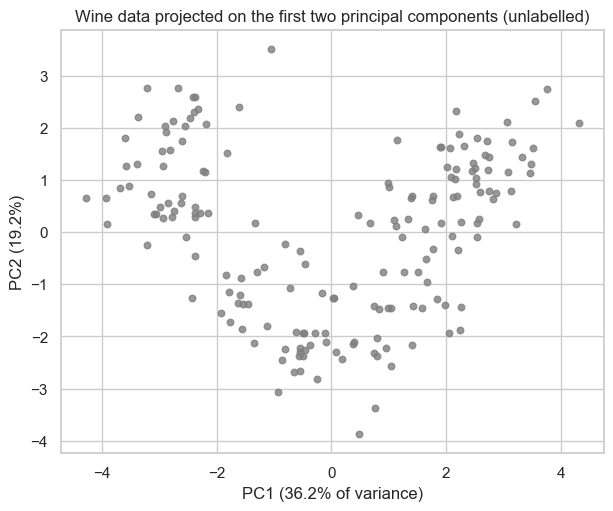

In [4]:
pca_w = PCA(2, random_state=SEED).fit(Xw)
Zw = pca_w.transform(Xw)
results['q1_pca_var'] = pca_w.explained_variance_ratio_.round(4).tolist()
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(Zw[:, 0], Zw[:, 1], s=22, c='tab:gray', alpha=0.8)
ax.set_xlabel(f'PC1 ({pca_w.explained_variance_ratio_[0]:.1%} of variance)'); ax.set_ylabel(f'PC2 ({pca_w.explained_variance_ratio_[1]:.1%})')
ax.set_title('Wine data projected on the first two principal components (unlabelled)')
savefig('q1a_pca'); plt.show()

In the PCA plane the points form an arc with **three dense groups**: left, bottom-centre and right, separated by sparser gaps. So **k = 3** looks best: 2 would merge two visible groups, and 4 or more would split a compact group in two.

### b. k-means with k = 3, clusters and centroids

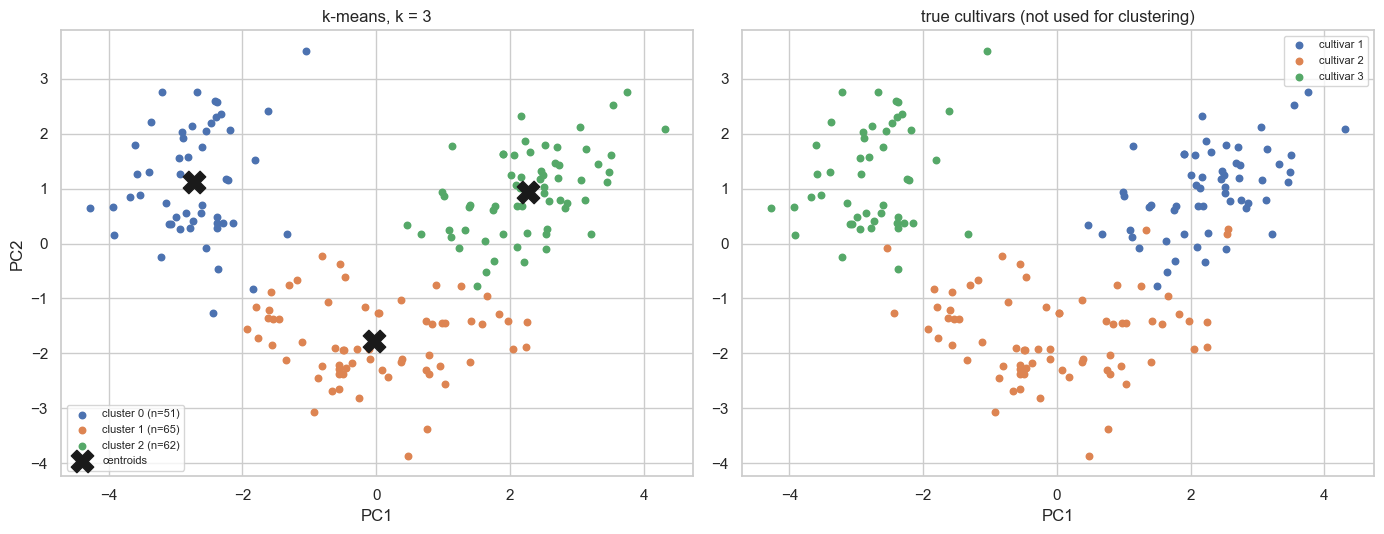

cluster sizes: [51 65 62] | adjusted Rand index vs cultivar: 0.8975


cluster,0,1,2
cultivar,,,
1,0,0,59
2,3,65,3
3,48,0,0


In [5]:
km3 = KMeans(3, n_init=20, random_state=SEED).fit(Xw)
cent_2d = pca_w.transform(km3.cluster_centers_)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for k in range(3):
    m = km3.labels_ == k
    ax[0].scatter(Zw[m, 0], Zw[m, 1], s=22, label=f'cluster {k} (n={m.sum()})')
ax[0].scatter(cent_2d[:, 0], cent_2d[:, 1], marker='X', s=260, c='k', label='centroids')
ax[0].set_title('k-means, k = 3'); ax[0].legend(fontsize=8); ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2')
for c in np.unique(cultivar):
    m = cultivar == c
    ax[1].scatter(Zw[m, 0], Zw[m, 1], s=22, label=f'cultivar {c}')
ax[1].set_title('true cultivars (not used for clustering)'); ax[1].legend(fontsize=8); ax[1].set_xlabel('PC1')
plt.tight_layout(); savefig('q1b_kmeans'); plt.show()
ari = adjusted_rand_score(cultivar, km3.labels_)
results['q1_k3'] = {'sizes': np.bincount(km3.labels_).tolist(), 'ari_vs_cultivar': float(ari), 'inertia': float(km3.inertia_)}
print('cluster sizes:', np.bincount(km3.labels_), '| adjusted Rand index vs cultivar:', round(ari, 4))
pd.crosstab(pd.Series(cultivar, name='cultivar'), pd.Series(km3.labels_, name='cluster'))

### c–d. Silhouette score and the elbow method

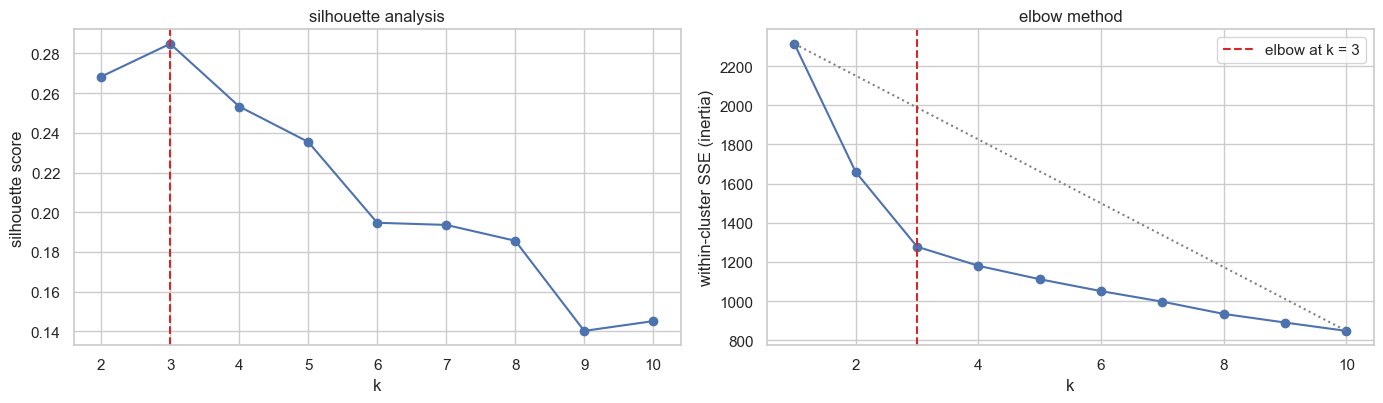

silhouette: {'2': 0.2683, '3': 0.2849, '4': 0.2533, '5': 0.2354, '6': 0.1947, '7': 0.1936, '8': 0.1856, '9': 0.1402, '10': 0.1451}
best k: silhouette → 3 | elbow → 3


In [6]:
ks = range(2, 11)
sil, inertia = [], []
for k in ks:
    m = KMeans(k, n_init=20, random_state=SEED).fit(Xw)
    sil.append(silhouette_score(Xw, m.labels_)); inertia.append(m.inertia_)
inertia_k1 = KMeans(1, n_init=1, random_state=SEED).fit(Xw).inertia_
ks_all, inertia_all = [1] + list(ks), [inertia_k1] + inertia
# elbow: point of maximum distance from the line joining the first and last points of the curve
p1, p2 = np.array([ks_all[0], inertia_all[0]]), np.array([ks_all[-1], inertia_all[-1]])
pts = np.column_stack([ks_all, inertia_all])
d = p2 - p1
dist = np.abs(d[0] * (p1[1] - pts[:, 1]) - d[1] * (p1[0] - pts[:, 0])) / np.linalg.norm(d)   # 2-D cross product
elbow_k = ks_all[int(dist.argmax())]
results['q1_silhouette'] = dict(zip(map(str, ks), np.round(sil, 4).tolist()))
results['q1_inertia'] = dict(zip(map(str, ks_all), np.round(inertia_all, 2).tolist()))
results['q1_best'] = {'silhouette_k': int(list(ks)[int(np.argmax(sil))]), 'elbow_k': int(elbow_k)}

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(list(ks), sil, 'o-'); ax[0].axvline(results['q1_best']['silhouette_k'], ls='--', c='tab:red')
ax[0].set_xlabel('k'); ax[0].set_ylabel('silhouette score'); ax[0].set_title('silhouette analysis')
ax[1].plot(ks_all, inertia_all, 'o-'); ax[1].plot([p1[0], p2[0]], [p1[1], p2[1]], ':', c='grey')
ax[1].axvline(elbow_k, ls='--', c='tab:red', label=f'elbow at k = {elbow_k}')
ax[1].set_xlabel('k'); ax[1].set_ylabel('within-cluster SSE (inertia)'); ax[1].set_title('elbow method'); ax[1].legend()
plt.tight_layout(); savefig('q1cd_k_selection'); plt.show()
print('silhouette:', results['q1_silhouette']); print('best k: silhouette →', results['q1_best']['silhouette_k'], '| elbow →', elbow_k)

# Question 2 — k-means from scratch on Fashion-MNIST

In [7]:
def read_idx(path):
    with gzip.open(path, 'rb') as f:
        data = f.read()
    ndim = data[3]
    shape = [int.from_bytes(data[4 + 4 * i: 8 + 4 * i], 'big') for i in range(ndim)]
    return np.frombuffer(data, dtype=np.uint8, offset=4 + 4 * ndim).reshape(shape)

X_img = read_idx('data/fashion_mnist/train-images-idx3-ubyte.gz')
y_fm = read_idx('data/fashion_mnist/train-labels-idx1-ubyte.gz')
FM_CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
Xf = X_img.reshape(len(X_img), -1).astype(np.float64) / 255.0          # flatten to 784-d, scale pixels to [0, 1]
print(Xf.shape, '| pixel range', Xf.min(), '–', Xf.max(), '| images per class:', np.bincount(y_fm))

(60000, 784) | pixel range 0.0 – 1.0 | images per class: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


The 60 000 training images are flattened to 784-dimensional vectors and scaled from 0–255 to [0, 1]. Scaling doesn't change which centre is nearest, but it keeps the squared distances (and the SSE) in a readable range, and it makes the "input range" for random initialisation simply [0, 1].

### a–b. The `KMeans` class
- stores the cluster centres (`centers_`) and point assignments (`labels_`);
- takes **k** from the user;
- optionally takes **initial centres** from the user (otherwise it picks k random data points);
- stops when the centres **stop changing** (largest shift < `tol`) or after `max_iter` iterations.

Distances use the identity ‖x − c‖² = ‖x‖² − 2x·c + ‖c‖², so each iteration is one 60 000 × 784 by 784 × k matrix product. If a cluster loses all its points, its centre is kept where it is (no mean of an empty set) and the count is reported.

In [8]:
class KMeansScratch:
    def __init__(self, k, init_centers=None, max_iter=300, tol=1e-6, seed=SEED):
        self.k, self.init_centers, self.max_iter, self.tol, self.seed = k, init_centers, max_iter, tol, seed

    @staticmethod
    def _sq_dist(X, C):
        return (X ** 2).sum(1)[:, None] - 2 * X @ C.T + (C ** 2).sum(1)[None, :]

    def fit(self, X):
        if self.init_centers is not None:
            C = np.array(self.init_centers, dtype=float).copy()
            assert C.shape == (self.k, X.shape[1]), 'need k initial centres with the same dimension as X'
        else:
            C = X[np.random.default_rng(self.seed).choice(len(X), self.k, replace=False)].copy()
        self.history_ = []
        for it in range(1, self.max_iter + 1):
            labels = self._sq_dist(X, C).argmin(1)
            new_C = C.copy()
            for j in range(self.k):
                members = labels == j
                if members.any():
                    new_C[j] = X[members].mean(0)
            shift = np.sqrt(((new_C - C) ** 2).sum(1)).max()
            C = new_C
            self.history_.append({'iteration': it, 'max centre shift': shift, 'SSE': self.sse(X, C, labels)})
            if shift < self.tol:
                break
        self.centers_, self.n_iter_ = C, it
        self.labels_ = self._sq_dist(X, C).argmin(1)
        self.converged_ = shift < self.tol
        return self

    def predict(self, X):
        return self._sq_dist(X, self.centers_).argmin(1)

    @staticmethod
    def sse(X, C, labels):
        return float(sum(((X[labels == j] - C[j]) ** 2).sum() for j in range(len(C))))

    def counts(self):
        return np.bincount(self.labels_, minlength=self.k)

### c. k = 10, initialised with 10 random points in the input range

In [9]:
rng = np.random.default_rng(SEED)
random_init = rng.uniform(0, 1, size=(10, 784))           # random 784-d points inside [0, 1]^784
t0 = time.time()
km_rand = KMeansScratch(10, init_centers=random_init, max_iter=300).fit(Xf)
counts_rand = km_rand.counts()
results['q2c'] = {'counts': counts_rand.tolist(), 'iterations': km_rand.n_iter_, 'converged': bool(km_rand.converged_),
                  'empty_clusters': int((counts_rand == 0).sum()), 'seconds': round(time.time() - t0, 1)}
print(f'converged: {km_rand.converged_} after {km_rand.n_iter_} iterations ({time.time() - t0:.1f}s)')
print('points per cluster:', counts_rand.tolist())

converged: True after 41 iterations (5.2s)
points per cluster: [7660, 8995, 4270, 4307, 8195, 7253, 6137, 6561, 2904, 3718]


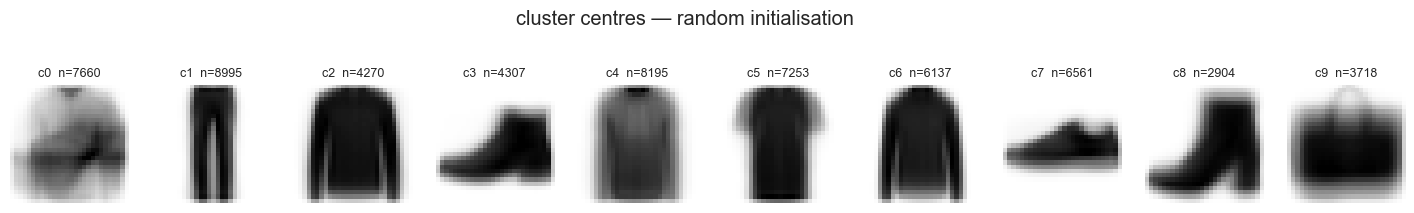

In [10]:
def show_centers(C, counts, title, name):
    fig, ax = plt.subplots(1, len(C), figsize=(18, 2.3))
    for j, a in enumerate(ax):
        a.imshow(C[j].reshape(28, 28), cmap='gray_r'); a.set_title(f'c{j}  n={counts[j]}', fontsize=9); a.axis('off')
    fig.suptitle(title, y=1.08); savefig(name); plt.show()

def show_members(model, title, name, per=10):
    fig, ax = plt.subplots(model.k, per, figsize=(per * 1.1, model.k * 1.15))
    r = np.random.default_rng(SEED)
    for j in range(model.k):
        idx = np.nonzero(model.labels_ == j)[0]
        pick = r.choice(idx, min(per, len(idx)), replace=False) if len(idx) else []
        for i in range(per):
            a = ax[j, i]; a.axis('off')
            if i < len(pick):
                a.imshow(Xf[pick[i]].reshape(28, 28), cmap='gray_r')
        ax[j, 0].text(-6, 14, f'c{j}', fontsize=9, ha='right', va='center')
    fig.suptitle(title, y=1.0); plt.tight_layout(); savefig(name); plt.show()

show_centers(km_rand.centers_, counts_rand, 'cluster centres — random initialisation', 'q2d_centers_random')

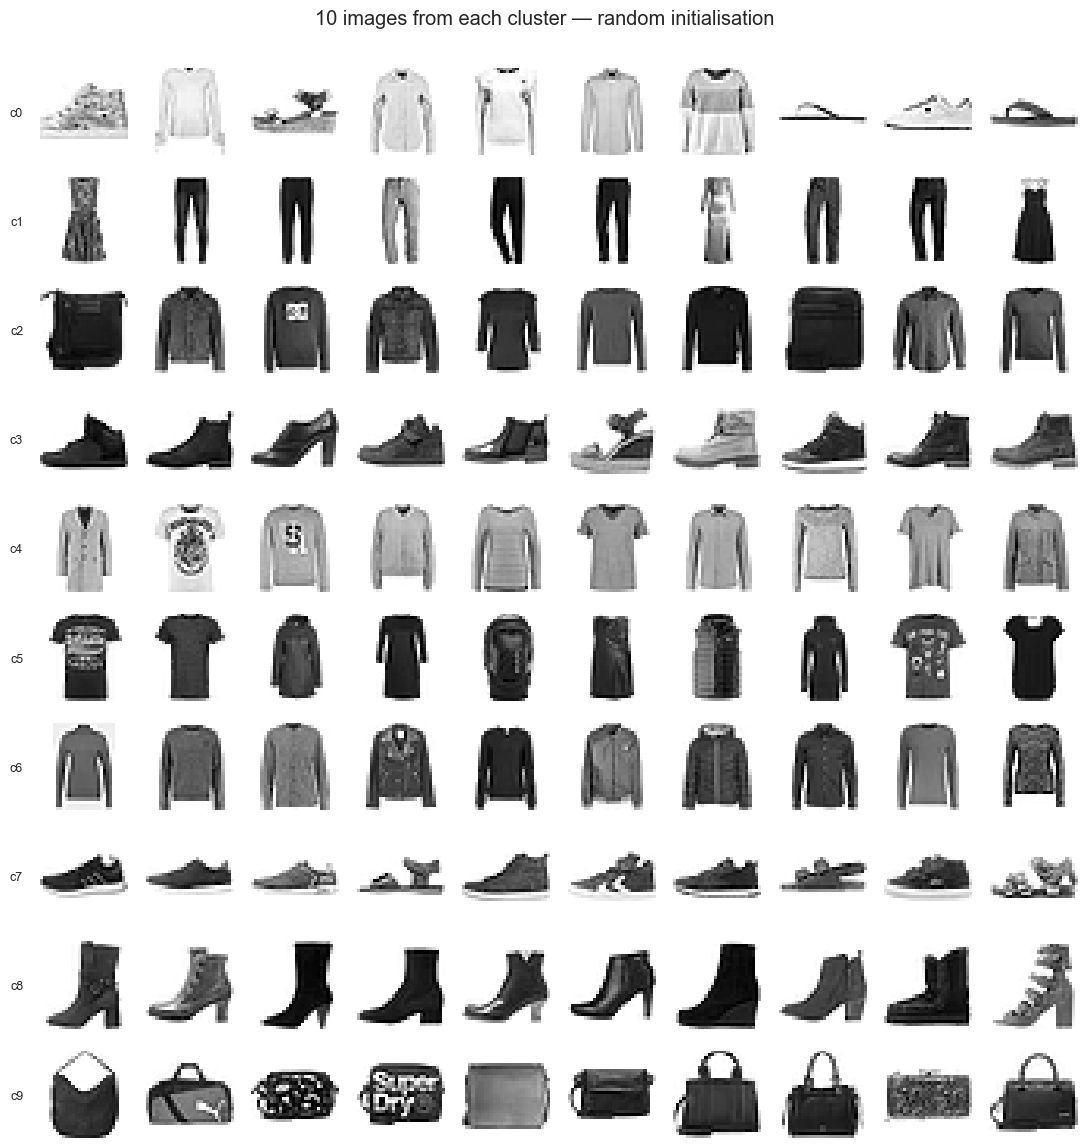

In [11]:
show_members(km_rand, '10 images from each cluster — random initialisation', 'q2e_members_random')

### f–g. k = 10, initialised with one image from each of the 10 classes
"10 images from each class" is implemented as **10 initial centres, one image from each class**: for every class, the first image of that class in the training set is used. Each centre therefore starts inside a different class's region.

converged: True after 155 iterations (19.3s)
points per cluster: [6380, 5228, 9534, 5194, 7306, 8010, 2542, 7620, 2356, 5830]


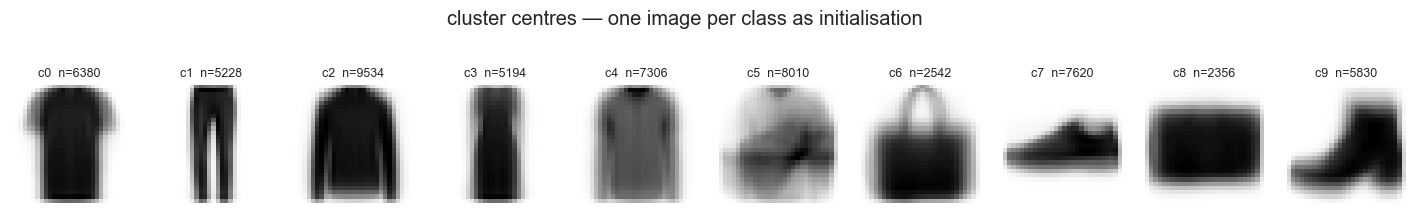

In [12]:
class_init = np.array([Xf[np.nonzero(y_fm == c)[0][0]] for c in range(10)])
t0 = time.time()
km_cls = KMeansScratch(10, init_centers=class_init, max_iter=300).fit(Xf)
counts_cls = km_cls.counts()
results['q2f'] = {'counts': counts_cls.tolist(), 'iterations': km_cls.n_iter_, 'converged': bool(km_cls.converged_),
                  'empty_clusters': int((counts_cls == 0).sum()), 'seconds': round(time.time() - t0, 1)}
print(f'converged: {km_cls.converged_} after {km_cls.n_iter_} iterations ({time.time() - t0:.1f}s)')
print('points per cluster:', counts_cls.tolist())
show_centers(km_cls.centers_, counts_cls, 'cluster centres — one image per class as initialisation', 'q2f_centers_class')

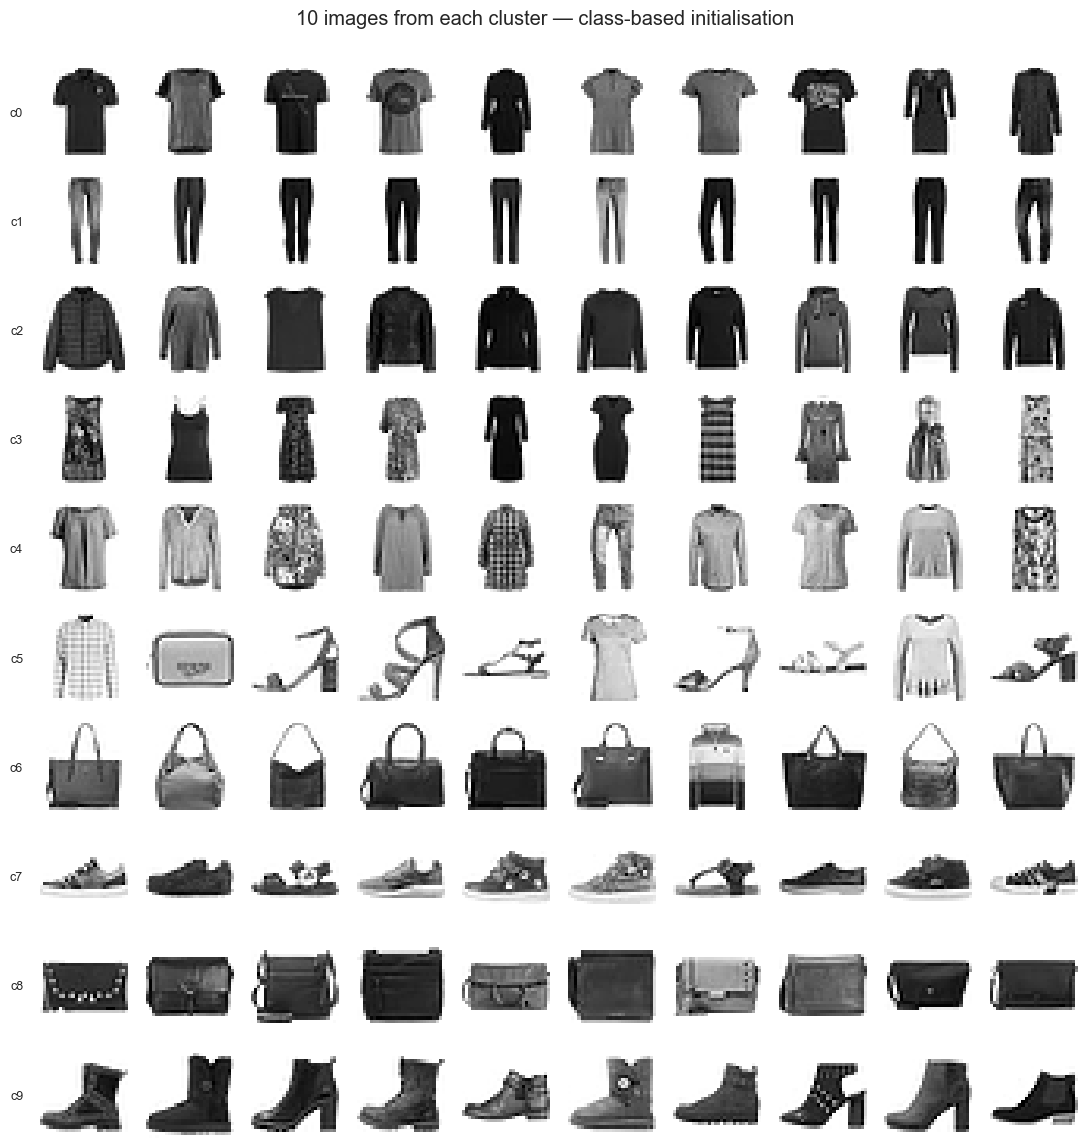

In [13]:
show_members(km_cls, '10 images from each cluster — class-based initialisation', 'q2g_members_class')

### h. Sum of squared errors

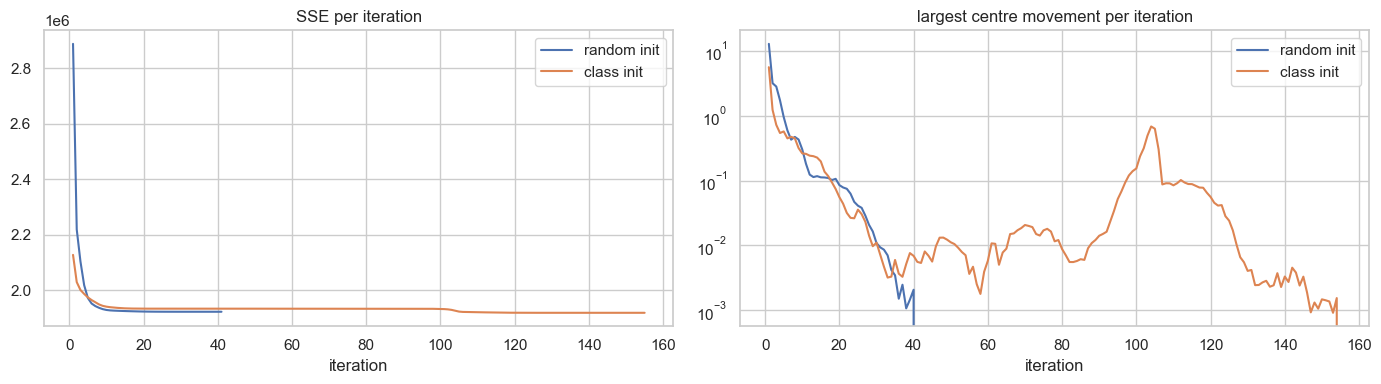

,SSE,non-empty clusters,iterations,purity vs labels,ARI vs labels
random init (c),1.923418e+06,10.0,41.0,0.5556,0.3423
class init (f),1.919627e+06,10.0,155.0,0.6113,0.4024


In [14]:
def purity(labels, y):
    return sum(np.bincount(y[labels == j]).max() for j in np.unique(labels)) / len(y)

sse_rand, sse_cls = KMeansScratch.sse(Xf, km_rand.centers_, km_rand.labels_), KMeansScratch.sse(Xf, km_cls.centers_, km_cls.labels_)
summary = pd.DataFrame({
    'random init (c)': {'SSE': sse_rand, 'non-empty clusters': int((counts_rand > 0).sum()), 'iterations': km_rand.n_iter_,
                        'purity vs labels': purity(km_rand.labels_, y_fm), 'ARI vs labels': adjusted_rand_score(y_fm, km_rand.labels_)},
    'class init (f)': {'SSE': sse_cls, 'non-empty clusters': int((counts_cls > 0).sum()), 'iterations': km_cls.n_iter_,
                       'purity vs labels': purity(km_cls.labels_, y_fm), 'ARI vs labels': adjusted_rand_score(y_fm, km_cls.labels_)}}).T
results['q2h'] = summary.round(4).to_dict('index')

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for model, lbl in [(km_rand, 'random init'), (km_cls, 'class init')]:
    h = pd.DataFrame(model.history_)
    ax[0].plot(h['iteration'], h['SSE'], label=lbl); ax[1].semilogy(h['iteration'], h['max centre shift'], label=lbl)
ax[0].set_title('SSE per iteration'); ax[1].set_title('largest centre movement per iteration')
for a in ax: a.set_xlabel('iteration'); a.legend()
plt.tight_layout(); savefig('q2h_convergence'); plt.show()

ct = pd.crosstab(pd.Series(km_cls.labels_, name='cluster'), pd.Series(np.array(FM_CLASSES)[y_fm], name='class'))
results['q2_class_cluster_major'] = {int(j): ct.loc[j].idxmax() for j in ct.index}
summary.round(4)

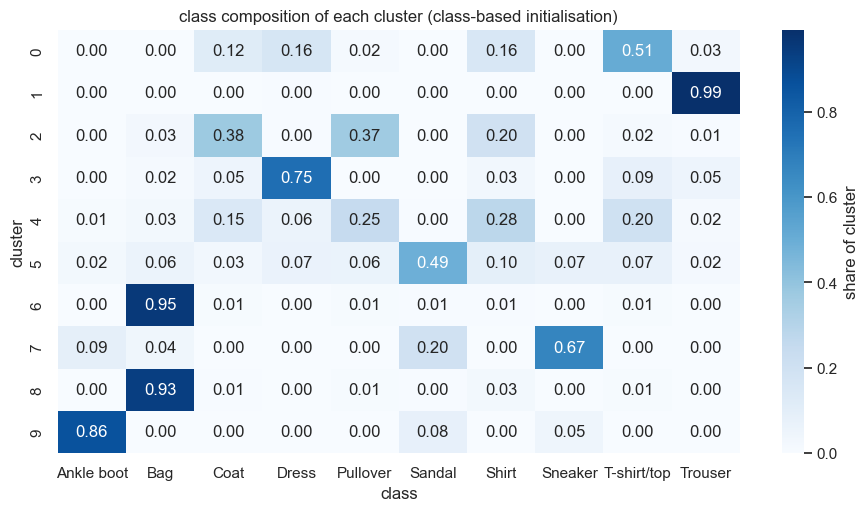

In [15]:
ct_share = ct.div(ct.sum(1), axis=0)
plt.figure(figsize=(11, 5.5))
sns.heatmap(ct_share, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'share of cluster'})
plt.title('class composition of each cluster (class-based initialisation)'); savefig('q2_composition'); plt.show()

# Question 3 — Hierarchical clustering on the brain MRI dataset (Br35H)

### A. The dataset and normalisation
3 000 brain MRI slices (1 500 with a tumour, 1 500 without). The originals come in 291 different sizes, from 150 × 167 to 1920 × 1427 pixels, so each image was converted once to 64 × 64 greyscale (`data/Q3/br35h_64x64.npz`). Each image is then a vector of 4 096 pixel **variables**. They are normalised by standardising every pixel position to zero mean and unit variance across the dataset, so a bright border region cannot dominate the distances. The tumour label is kept aside and used only for evaluation.

(3000, 64, 64) | tumour / healthy: [1500 1500] | standardised matrix: (3000, 4096)


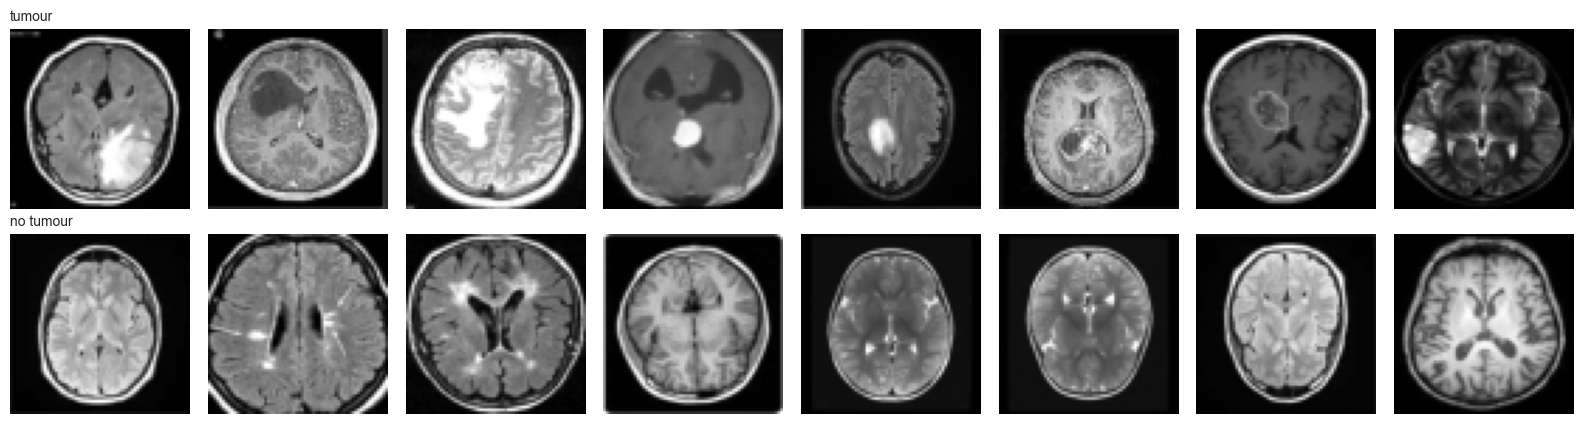

In [16]:
br = np.load('data/Q3/br35h_64x64.npz')
imgs, tumour = br['images'], br['tumour']
Xb = StandardScaler().fit_transform(imgs.reshape(len(imgs), -1).astype(float))
print(imgs.shape, '| tumour / healthy:', np.bincount(tumour)[::-1], '| standardised matrix:', Xb.shape)

fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
r = np.random.default_rng(SEED)
for row, lab in enumerate([1, 0]):
    for a, i in zip(ax[row], r.choice(np.nonzero(tumour == lab)[0], 8, replace=False)):
        a.imshow(imgs[i], cmap='gray'); a.axis('off')
    ax[row, 0].set_title('tumour' if lab else 'no tumour', loc='left', fontsize=10)
plt.tight_layout(); savefig('q3a_samples'); plt.show()

### B–C. Dimension reduction, how many communities, and what they look like

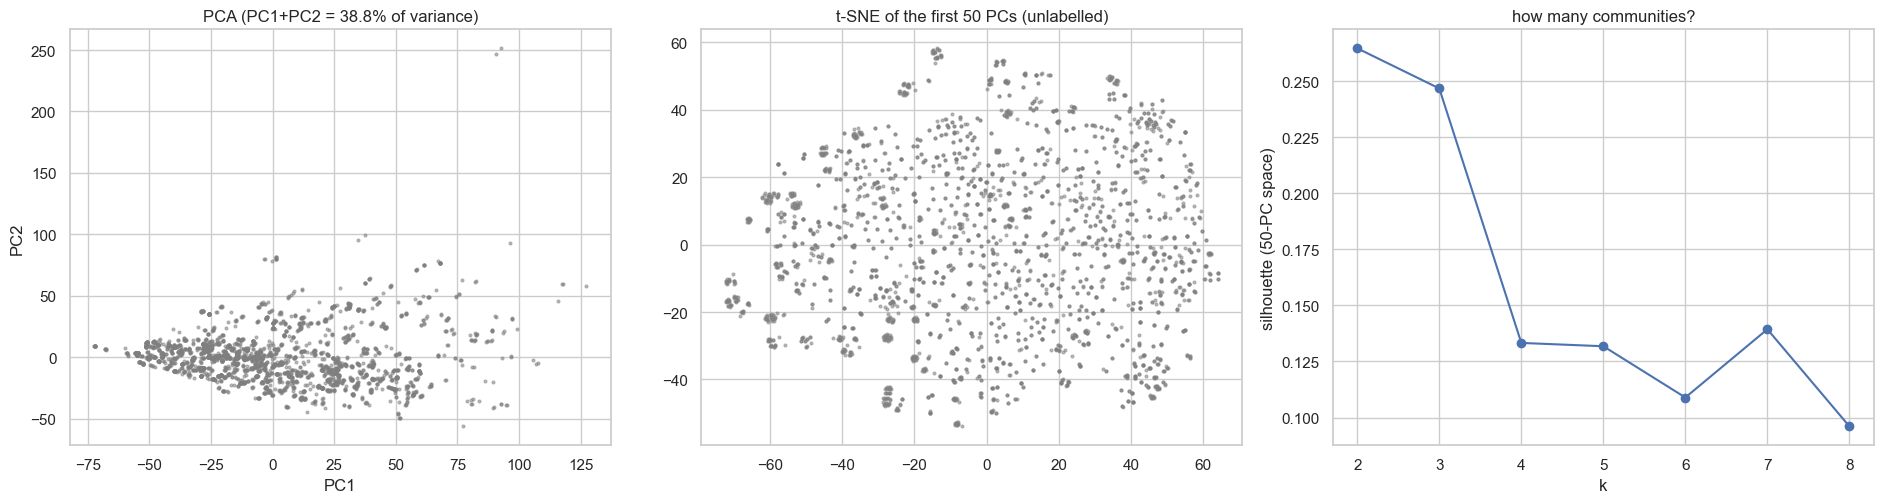

{2: np.float64(0.2648), 3: np.float64(0.2469), 4: np.float64(0.1333), 5: np.float64(0.1318), 6: np.float64(0.1089), 7: np.float64(0.1394), 8: np.float64(0.0961)}


In [17]:
pca_b = PCA(50, random_state=SEED).fit(Xb)
Zb = pca_b.transform(Xb)
cum = np.cumsum(pca_b.explained_variance_ratio_)
from sklearn.manifold import TSNE
Tb = TSNE(2, perplexity=40, init='pca', random_state=SEED).fit_transform(Zb)
results['q3_pca'] = {'pc1': float(pca_b.explained_variance_ratio_[0]), 'pc2': float(pca_b.explained_variance_ratio_[1]),
                     'cum50': float(cum[-1])}

sil_b = {k: silhouette_score(Zb, KMeans(k, n_init=10, random_state=SEED).fit_predict(Zb)) for k in range(2, 9)}
results['q3_silhouette'] = {str(k): round(v, 4) for k, v in sil_b.items()}

fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
ax[0].scatter(Zb[:, 0], Zb[:, 1], s=4, c='tab:gray', alpha=0.5); ax[0].set_title(f'PCA (PC1+PC2 = {cum[1]:.1%} of variance)')
ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2')
ax[1].scatter(Tb[:, 0], Tb[:, 1], s=4, c='tab:gray', alpha=0.5); ax[1].set_title('t-SNE of the first 50 PCs (unlabelled)')
ax[2].plot(list(sil_b), list(sil_b.values()), 'o-'); ax[2].set_xlabel('k'); ax[2].set_ylabel('silhouette (50-PC space)')
ax[2].set_title('how many communities?')
plt.tight_layout(); savefig('q3b_reduction'); plt.show()
print({k: round(v, 4) for k, v in sil_b.items()})

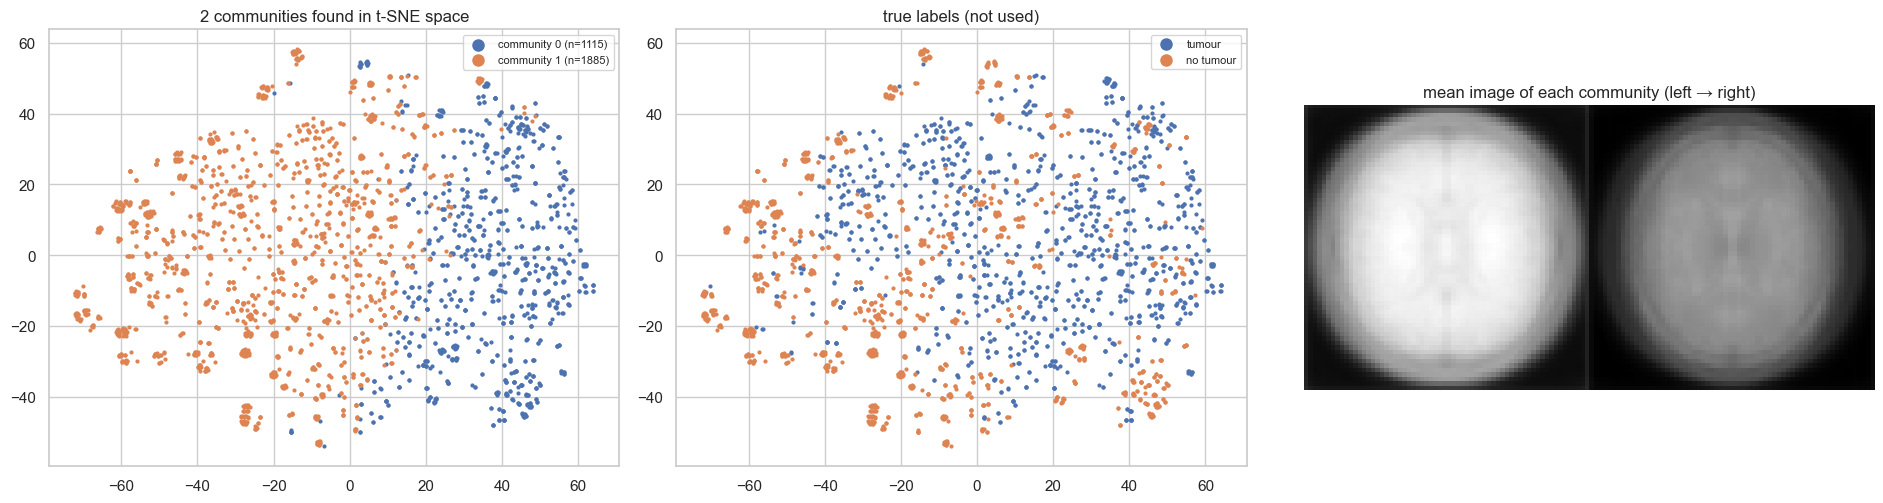

In [18]:
N_COMM = max(sil_b, key=sil_b.get)
results['q3_n_communities'] = int(N_COMM)
comm = KMeans(N_COMM, n_init=20, random_state=SEED).fit_predict(Zb)
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))
for k in range(N_COMM):
    m = comm == k
    ax[0].scatter(Tb[m, 0], Tb[m, 1], s=4, label=f'community {k} (n={m.sum()})')
ax[0].legend(markerscale=4, fontsize=8); ax[0].set_title(f'{N_COMM} communities found in t-SNE space')
for lab, name in [(1, 'tumour'), (0, 'no tumour')]:
    m = tumour == lab
    ax[1].scatter(Tb[m, 0], Tb[m, 1], s=4, label=name)
ax[1].legend(markerscale=4, fontsize=8); ax[1].set_title('true labels (not used)')
mean_imgs = np.hstack([imgs[comm == k].mean(0) for k in range(N_COMM)])
ax[2].imshow(mean_imgs, cmap='gray'); ax[2].axis('off'); ax[2].set_title('mean image of each community (left → right)')
plt.tight_layout(); savefig('q3c_communities'); plt.show()

### D–E. Agglomerative hierarchical clustering vs k-means

In [19]:
from scipy.cluster.hierarchy import linkage, dendrogram
t0 = time.time()
agg = AgglomerativeClustering(n_clusters=N_COMM, linkage='ward').fit(Zb)
t_agg = time.time() - t0
t0 = time.time()
km_b = KMeans(N_COMM, n_init=20, random_state=SEED).fit(Zb)
t_km = time.time() - t0

def tumour_purity(labels):
    return sum(np.bincount(tumour[labels == j], minlength=2).max() for j in np.unique(labels)) / len(tumour)

comp = pd.DataFrame({
    'Agglomerative (Ward)': {'silhouette': silhouette_score(Zb, agg.labels_), 'ARI vs tumour label': adjusted_rand_score(tumour, agg.labels_),
                             'purity vs tumour label': tumour_purity(agg.labels_), 'cluster sizes': str(np.bincount(agg.labels_).tolist()), 'seconds': round(t_agg, 2)},
    'k-means': {'silhouette': silhouette_score(Zb, km_b.labels_), 'ARI vs tumour label': adjusted_rand_score(tumour, km_b.labels_),
                'purity vs tumour label': tumour_purity(km_b.labels_), 'cluster sizes': str(np.bincount(km_b.labels_).tolist()), 'seconds': round(t_km, 2)}}).T
agree = adjusted_rand_score(agg.labels_, km_b.labels_)
results['q3_compare'] = {k: {kk: (vv if isinstance(vv, str) else float(vv)) for kk, vv in v.items()} for k, v in comp.to_dict('index').items()}
results['q3_ari_between_methods'] = float(agree)
print('ARI between the two clusterings:', round(agree, 4))
comp

ARI between the two clusterings: 0.6269


,silhouette,ARI vs tumour label,purity vs tumour label,cluster sizes,seconds
Agglomerative (Ward),0.250899,0.068028,0.630667,"[936, 2064]",0.09
k-means,0.264774,0.100844,0.659,"[1115, 1885]",0.05


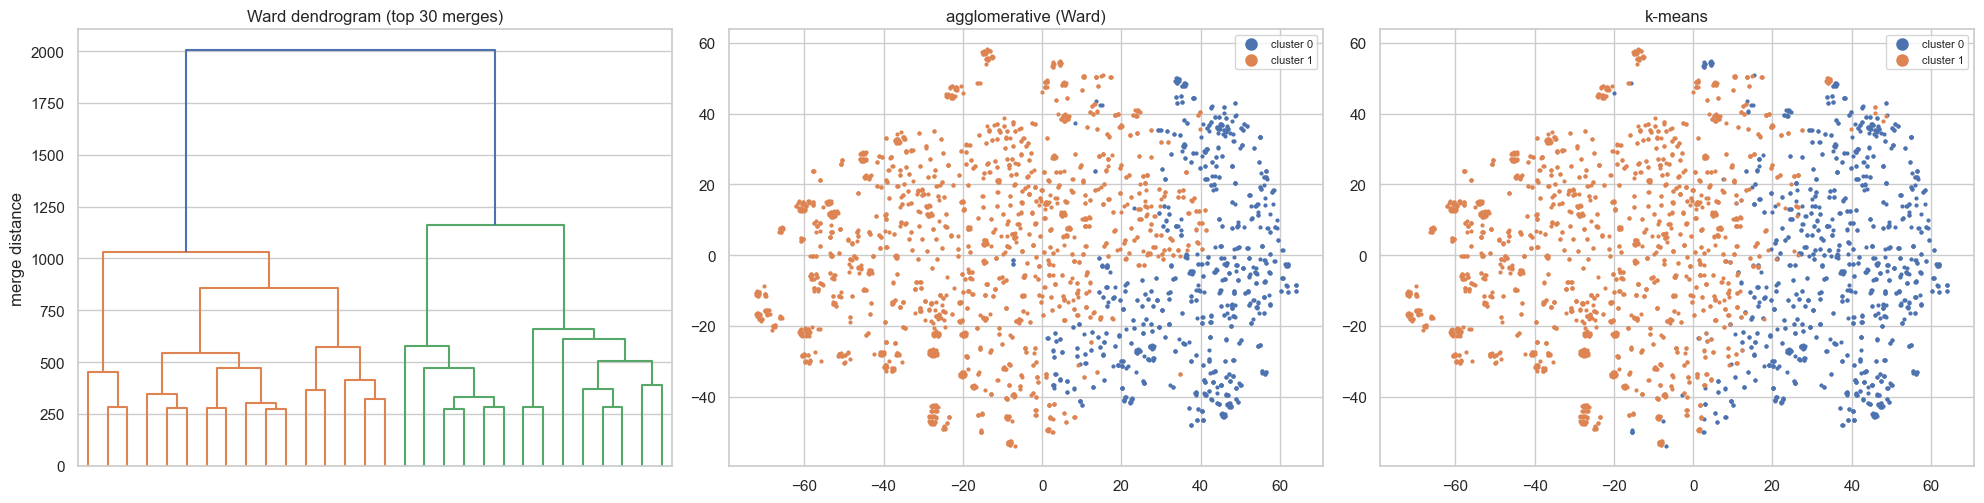

agglomerative
truth    no tumour  tumour
cluster                   
0              272     664
1             1228     836
k-means
truth    no tumour  tumour
cluster                   
0              319     796
1             1181     704


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5.2))
dendrogram(linkage(Zb, 'ward'), truncate_mode='lastp', p=30, ax=ax[0], no_labels=True, color_threshold=None)
ax[0].set_title('Ward dendrogram (top 30 merges)'); ax[0].set_ylabel('merge distance')
for a, lab, title in [(ax[1], agg.labels_, 'agglomerative (Ward)'), (ax[2], km_b.labels_, 'k-means')]:
    for k in range(N_COMM):
        m = lab == k
        a.scatter(Tb[m, 0], Tb[m, 1], s=4, label=f'cluster {k}')
    a.set_title(title); a.legend(markerscale=4, fontsize=8)
plt.tight_layout(); savefig('q3de_compare'); plt.show()

for name, lab in [('agglomerative', agg.labels_), ('k-means', km_b.labels_)]:
    print(name); print(pd.crosstab(pd.Series(lab, name='cluster'), pd.Series(np.where(tumour, 'tumour', 'no tumour'), name='truth')))

with open('results.json', 'w') as f:
    json.dump(results, f, indent=2, default=float)